In [5]:
# CODE 1 — Install Libraries

!pip install flask flask-cors pyngrok scikit-learn pandas numpy joblib

In [6]:
# CODE 2 — Upload Dataset

from google.colab import files

uploaded = files.upload()

Saving diabetes.csv to diabetes (1).csv


In [7]:
# CODE 3 — Load and Inspect Dataset

import pandas as pd

df = pd.read_csv("diabetes.csv")

print("Dataset shape:", df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nTarget distribution:")
print(df["Outcome"].value_counts())

df.head()

Dataset shape: (768, 9)

Columns:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age', 'Outcome']

Missing values:
Pregnancies                 0
Glucose                     0
BloodPressure               0
SkinThickness               0
Insulin                     0
BMI                         0
DiabetesPedigreeFunction    0
Age                         0
Outcome                     0
dtype: int64

Target distribution:
Outcome
0    500
1    268
Name: count, dtype: int64


,Pregnancies,Glucose,BloodPressure,SkinThickness,Insulin,BMI,DiabetesPedigreeFunction,Age,Outcome
0,6,148,72.0,35,169.5,33.6,0.627,50,1
1,1,85,66.0,29,102.5,26.6,0.351,31,0
2,8,183,64.0,32,169.5,23.3,0.672,32,1
3,1,89,66.0,23,94.0,28.1,0.167,21,0
4,0,137,40.0,35,168.0,43.1,2.288,33,1


In [8]:
# CODE 4 — Separate Input and Target

X = df.drop("Outcome", axis=1)
y = df["Outcome"]

print("Input features:")
print(X.columns.tolist())

print("\nTarget:")
print("Outcome")

Input features:
['Pregnancies', 'Glucose', 'BloodPressure', 'SkinThickness', 'Insulin', 'BMI', 'DiabetesPedigreeFunction', 'Age']

Target:
Outcome


In [9]:
# CODE 5 — Train Test Split

from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))

Training samples: 614
Testing samples: 154


In [10]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [11]:
# CODE 6 — Train Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

logistic_model.fit(X_train, y_train)

print("Logistic Regression trained successfully.")

Logistic Regression trained successfully.


In [12]:
# CODE 7 — Train Random Forest

from sklearn.ensemble import RandomForestClassifier

random_forest_model = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("model", RandomForestClassifier(
        n_estimators=200,
        random_state=42
    ))
])

random_forest_model.fit(X_train, y_train)

print("Random Forest trained successfully.")

Random Forest trained successfully.


In [13]:
# CODE 8 — Evaluate Models

from sklearn.metrics import accuracy_score, recall_score

models = {
    "Logistic Regression": logistic_model,
    "Random Forest": random_forest_model
}

results = {}

for name, model in models.items():

    predictions = model.predict(X_test)

    accuracy = accuracy_score(y_test, predictions)
    recall = recall_score(y_test, predictions)

    results[name] = {
        "Accuracy": accuracy,
        "Recall": recall
    }

    print("\n" + name)
    print("Accuracy:", round(accuracy, 4))
    print("Recall:", round(recall, 4))


Logistic Regression
Accuracy: 0.7078
Recall: 0.5556

Random Forest
Accuracy: 0.8701
Recall: 0.7963



 Logistic Regression
[[79 21]
 [24 30]]


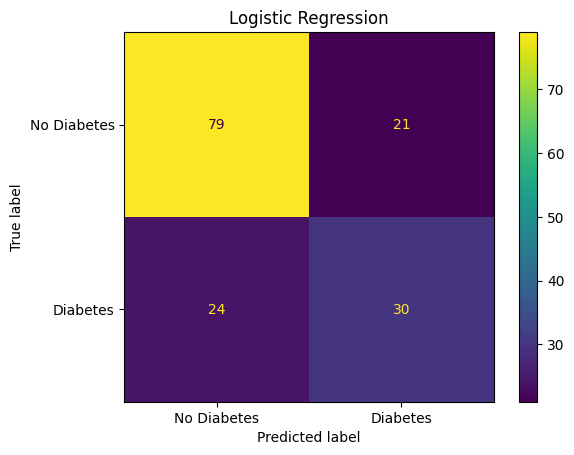


 Random Forest
[[91  9]
 [11 43]]


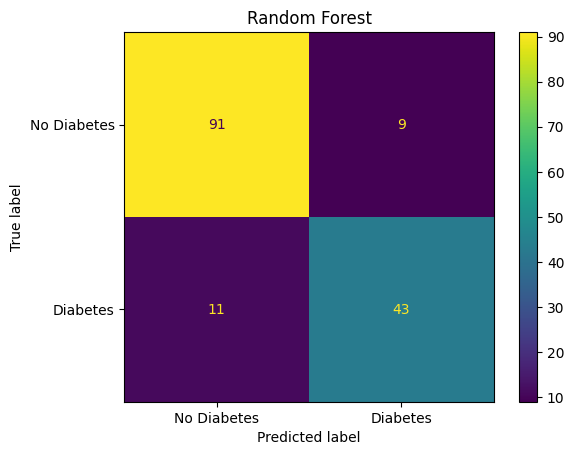

In [14]:
# CODE 9 — Confusion Matrix

from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in models.items():

    predictions = model.predict(X_test)

    cm = confusion_matrix(y_test, predictions)

    print("\n", name)
    print(cm)

    ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=["No Diabetes", "Diabetes"]
    ).plot()

    plt.title(name)
    plt.show()

In [15]:
# CODE 10 — Select Best Model

best_model_name = max(
    results,
    key=lambda name: results[name]["Recall"]
)

best_model = models[best_model_name]

print("Selected model:", best_model_name)
print("Accuracy:", results[best_model_name]["Accuracy"])
print("Recall:", results[best_model_name]["Recall"])

Selected model: Random Forest
Accuracy: 0.8701298701298701
Recall: 0.7962962962962963


In [16]:
# CODE 11 — Save Model

import joblib

joblib.dump(best_model, "diabetes_model.pkl")

print("Model saved successfully as diabetes_model.pkl")

Model saved successfully as diabetes_model.pkl


In [17]:
# CODE 12 — Verify Model

import os

if os.path.exists("diabetes_model.pkl"):
    print("diabetes_model.pkl exists.")
    print("Model file size:", os.path.getsize("diabetes_model.pkl"), "bytes")
else:
    print("ERROR: Model file was not created.")

diabetes_model.pkl exists.
Model file size: 2306738 bytes


In [18]:
# CODE 13 — Create Flask App

from flask import Flask, request, jsonify
from flask_cors import CORS
import joblib
import pandas as pd

app = Flask(__name__)

CORS(app)

model = joblib.load("diabetes_model.pkl")

print("Flask backend initialized.")

Flask backend initialized.


In [19]:
# CODE 14 — Home Route

@app.route("/", methods=["GET"])
def home():

    return jsonify({
        "message": "Diabetes Prediction API is running",
        "status": "success"
    })

In [20]:
# CODE 15 — Prediction Route

@app.route("/predict", methods=["POST"])
def predict():

    try:

        data = request.get_json()

        if not data:
            return jsonify({
                "error": "No JSON data received"
            }), 400

        required_features = [
            "Pregnancies",
            "Glucose",
            "BloodPressure",
            "SkinThickness",
            "Insulin",
            "BMI",
            "DiabetesPedigreeFunction",
            "Age"
        ]

        missing = [
            feature
            for feature in required_features
            if feature not in data
        ]

        if missing:
            return jsonify({
                "error": "Missing fields",
                "missing": missing
            }), 400

        input_data = pd.DataFrame([{
            feature: float(data[feature])
            for feature in required_features
        }])

        prediction = model.predict(input_data)[0]

        probability = model.predict_proba(input_data)[0][1]

        return jsonify({
            "prediction": int(prediction),
            "probability": round(float(probability), 4)
        })

    except Exception as e:

        return jsonify({
            "error": str(e)
        }), 500

In [21]:
# CODE 16 — Start Flask Server

from threading import Thread

def run_flask():

    app.run(
        host="0.0.0.0",
        port=5000,
        debug=False,
        use_reloader=False
    )

flask_thread = Thread(target=run_flask)

flask_thread.daemon = True

flask_thread.start()

print("Flask server started on port 5000.")

Flask server started on port 5000.


In [22]:
# CODE 17 — Test Flask Server

import requests

response = requests.get(
    "http://127.0.0.1:5000/"
)

print("Status code:", response.status_code)
print("Response:", response.json())

 * Serving Flask app '__main__'
 * Debug mode: off


INFO:werkzeug:WARNING: This is a development server. Do not use it in a production deployment. Use a production WSGI server instead.
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
INFO:werkzeug:Press CTRL+C to quit
INFO:werkzeug:127.0.0.1 - - [22/Oct/2026 05:52:15] "GET / HTTP/1.1" 200 -


Status code: 200
Response: {'message': 'Diabetes Prediction API is running', 'status': 'success'}


In [23]:
# CODE 18 — Configure ngrok

from pyngrok import ngrok
from getpass import getpass

NGROK_AUTH_TOKEN = getpass(
    "Enter your NEW ngrok auth token: "
)

ngrok.set_auth_token(NGROK_AUTH_TOKEN)

print("Ngrok authentication configured.")

Enter your NEW ngrok auth token: ··········
Ngrok authentication configured.


In [24]:
# CODE 19 — Create ngrok Tunnel

public_url = ngrok.connect(5000)

API_URL = str(public_url)

print("======================================")
print("Public API URL:")
print(API_URL)

print("\nPrediction Endpoint:")
print(API_URL + "/predict")
print("======================================")

Public API URL:
NgrokTunnel: "https://washer-backspace-eastward.ngrok-free.dev" -> "http://localhost:5000"

Prediction Endpoint:
NgrokTunnel: "https://washer-backspace-eastward.ngrok-free.dev" -> "http://localhost:5000"/predict


In [25]:
# FIX API_URL — use the existing ngrok tunnel

API_URL = public_url.public_url

print("API_URL:")
print(API_URL)

print("\nType:")
print(type(API_URL))

API_URL:
https://washer-backspace-eastward.ngrok-free.dev

Type:
<class 'str'>


In [26]:
# CODE 20 — Test Prediction API

import requests

api_url = API_URL + "/predict"

test_data = {
    "Pregnancies": 2,
    "Glucose": 120,
    "BloodPressure": 70,
    "SkinThickness": 25,
    "Insulin": 100,
    "BMI": 28.5,
    "DiabetesPedigreeFunction": 0.35,
    "Age": 25
}

response = requests.post(
    api_url,
    json=test_data,
    timeout=30
)

print("Status code:", response.status_code)
print("Response:", response.json())

INFO:werkzeug:127.0.0.1 - - [22/Oct/2026 05:52:25] "POST /predict HTTP/1.1" 200 -


Status code: 200
Response: {'prediction': 0, 'probability': 0.01}


In [27]:
# CODE 21 — Print Frontend API URL

print("======================================")
print("COPY THIS URL INTO script.js")
print("======================================")
print(API_URL)
print("======================================")

COPY THIS URL INTO script.js
https://washer-backspace-eastward.ngrok-free.dev
